## Question #6 a)
### Create a random split 80% of the dataset into training set and 20% into a test set. Train a categorical Naıve Bayes classifier with different values of smoothing hyperparameter α, common amongst all features, ranging from 2−15 to 25. Plot the predictive performance of the trained classifier on your test set, as measured by ROC AUC, accuracy, and F1 scores. Report the parameters of the model for the α value that maximizes the AUC.


Train: (6499, 22), Test: (1625, 22)
    alpha  log2_alpha      AUC  Accuracy       F1
 0.000031       -15.0 0.999985  0.996308 0.996178
 0.000061       -14.0 0.999970  0.995077 0.994898
 0.000122       -13.0 0.999951  0.994462 0.994257
 0.000244       -12.0 0.999932  0.994462 0.994257
 0.000488       -11.0 0.999909  0.993231 0.992971
 0.000977       -10.0 0.999880  0.993231 0.992971
 0.001953        -9.0 0.999847  0.992615 0.992327
 0.003906        -8.0 0.999804  0.991385 0.991037
 0.007812        -7.0 0.999750  0.991385 0.991037
 0.015625        -6.0 0.999683  0.991385 0.991037
 0.031250        -5.0 0.999531  0.987077 0.986495
 0.062500        -4.0 0.999323  0.984000 0.983226
 0.125000        -3.0 0.999020  0.976615 0.975293
 0.250000        -2.0 0.998591  0.964308 0.961792
 0.500000        -1.0 0.998060  0.956923 0.953519
 1.000000         0.0 0.997354  0.950769 0.946524
 2.000000         1.0 0.996423  0.943385 0.938089
 4.000000         2.0 0.995325  0.940308 0.934504
 8.000000     

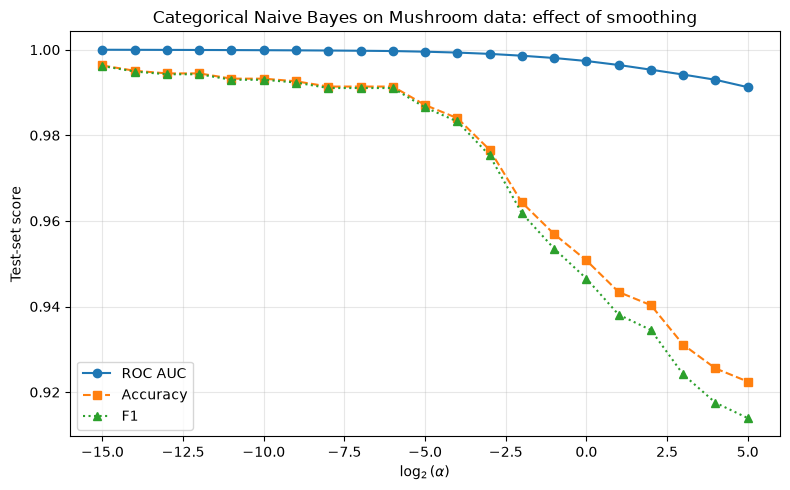


Best alpha = 2^-15 = 3.05176e-05 (AUC = 0.999985)

Class order: [0 1] (0 = edible, 1 = poisonous)
Class counts: [3365. 3134.]
Class priors P(y): [0.51777196 0.48222804]


'\nprint("\nP(feature = category | class) for each feature:")\nfor j, col in enumerate(X.columns):\n    probs = np.exp(best.feature_log_prob_[j])  # shape (n_classes, n_categories)\n    df = pd.DataFrame(probs.T, index=enc.categories_[j],\n                      columns=["P(.|edible)", "P(.|poisonous)"])\n    print(f"\n[{col}]")\n    print(df.round(4).to_string())\n'

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder
from sklearn.naive_bayes import CategoricalNB
from sklearn.metrics import roc_auc_score, accuracy_score, f1_score

SEED = 42

# ---------------------------------------------------------------- data
mushroom = fetch_ucirepo(id=73)
X = mushroom.data.features.copy()
y_raw = mushroom.data.targets.iloc[:, 0]

# 'stalk-root' has missing values: treat "missing" as its own category
X = X.fillna("missing")

# Target: 'p' (poisonous) = 1 (positive class), 'e' (edible) = 0
y = (y_raw == "p").astype(int).to_numpy()

# Encode categories as integers (CategoricalNB needs non-negative ints).
# Fitting the encoder on all rows only builds the category -> integer mapping,
# which guarantees a category that appears only in the test set doesn't crash.
enc = OrdinalEncoder()
X_enc = enc.fit_transform(X).astype(int)
n_cats = [len(c) for c in enc.categories_]

X_train, X_test, y_train, y_test = train_test_split(
    X_enc, y, test_size=0.20, random_state=SEED
)
print(f"Train: {X_train.shape}, Test: {X_test.shape}")

# ---------------------------------------------------------------- sweep
alphas = 2.0 ** np.arange(-15, 6)  # 2^-15, ..., 2^5
aucs, accs, f1s = [], [], []

for a in alphas:
    nb = CategoricalNB(alpha=a, min_categories=n_cats)
    nb.fit(X_train, y_train)
    proba = nb.predict_proba(X_test)[:, 1]
    pred = nb.predict(X_test)
    aucs.append(roc_auc_score(y_test, proba))
    accs.append(accuracy_score(y_test, pred))
    f1s.append(f1_score(y_test, pred))

results = pd.DataFrame({"alpha": alphas, "log2_alpha": np.log2(alphas),
                        "AUC": aucs, "Accuracy": accs, "F1": f1s})
print(results.to_string(index=False))

# ---------------------------------------------------------------- plot
plt.figure(figsize=(8, 5))
plt.plot(results.log2_alpha, results.AUC, "o-", label="ROC AUC")
plt.plot(results.log2_alpha, results.Accuracy, "s--", label="Accuracy")
plt.plot(results.log2_alpha, results.F1, "^:", label="F1")
plt.xlabel(r"$\log_2(\alpha)$")
plt.ylabel("Test-set score")
plt.title("Categorical Naive Bayes on Mushroom data: effect of smoothing")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("mushroom_nb_alpha_sweep.png", dpi=150)
plt.show()

# ---------------------------------------------------------------- best model
best_idx = int(np.argmax(aucs))  # first alpha achieving the max AUC
best_alpha = alphas[best_idx]
print(f"\nBest alpha = 2^{np.log2(best_alpha):.0f} = {best_alpha:.6g} "
      f"(AUC = {aucs[best_idx]:.6f})")

best = CategoricalNB(alpha=best_alpha, min_categories=n_cats).fit(X_train, y_train)

print("\nClass order:", best.classes_, "(0 = edible, 1 = poisonous)")
print("Class counts:", best.class_count_)
print("Class priors P(y):", np.exp(best.class_log_prior_))

print("\nP(feature = category | class) for each feature:")
for j, col in enumerate(X.columns):
    probs = np.exp(best.feature_log_prob_[j])  # shape (n_classes, n_categories)
    df = pd.DataFrame(probs.T, index=enc.categories_[j],
                      columns=["P(.|edible)", "P(.|poisonous)"])
    print(f"\n[{col}]")
    print(df.round(4).to_string())


## Question #6 b)
### Repeat the same experiment with split in which you use only 1% of the dataset for training, and 99% of the dataset for testing. In this case, you should be careful about dealing with missing categories in the training set. What differences do you see?

With a training set of 1% of data, then a significant number of categories will not be accounted for in the training data and the code must anticipate such omissions.  

Training rows: 81  Test rows: 8043


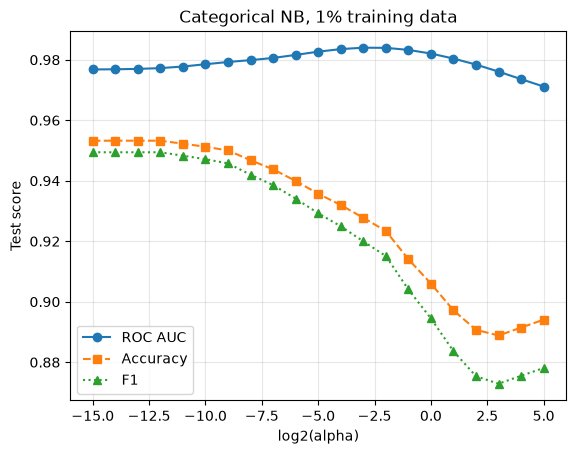

Best alpha: 2^-3 = 0.125, AUC = 0.9840
Class priors [edible, poisonous]: [0.56790123 0.43209877]

Feature: cap-shape
[[0.0882 0.0027 0.3877 0.0241 0.0241 0.4733]
 [0.0035 0.0035 0.3392 0.2552 0.0035 0.3951]]

Feature: cap-surface
[[0.3683 0.0027 0.2392 0.3898]
 [0.2007 0.0035 0.3134 0.4824]]

Feature: cap-color
[[0.0026 0.0026 0.1508 0.1931 0.4471 0.0238 0.0026 0.0026 0.0873 0.0873]
 [0.0034 0.0034 0.2793 0.2517 0.2793 0.0034 0.0034 0.0034 0.0862 0.0862]]

Feature: bruises
[[0.3703 0.6297]
 [0.9113 0.0887]]

Feature: odor
[[0.0451 0.0027 0.0027 0.0875 0.0027 0.8515 0.0027 0.0027 0.0027]
 [0.0035 0.1142 0.4464 0.0035 0.0035 0.0035 0.0588 0.1972 0.1696]]

Feature: gill-attachment
[[0.1108 0.8892]
 [0.0035 0.9965]]

Feature: gill-spacing
[[0.7811 0.2189]
 [0.883  0.117 ]]

Feature: gill-size
[[0.9541 0.0459]
 [0.2872 0.7128]]

Feature: gill-color
[[0.0026 0.0658 0.0447 0.0447 0.0868 0.1711 0.0658 0.15   0.0026 0.1289
  0.1921 0.0447]
 [0.524  0.0034 0.0582 0.0856 0.0034 0.0582 0.0034 0.25

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import CategoricalNB
from sklearn.metrics import roc_auc_score, accuracy_score, f1_score

# 1. Load the data ---------------------------------------------------------
mushroom = fetch_ucirepo(id=73)
X = mushroom.data.features
y = mushroom.data.targets.iloc[:, 0]

X = X.fillna("missing")           # one column has missing values; make "missing" its own category
y = (y == "p").astype(int)        # 1 = poisonous, 0 = edible

# 2. Turn letters into numbers ---------------------------------------------
# CategoricalNB needs integers. We do this on the WHOLE dataset (before splitting)
# so every possible category gets a number, even ones that won't be in the training set.
for col in X.columns:
    X[col] = X[col].astype("category").cat.codes

# 3. Tell the model how many categories each feature has --------------------
# With only 1% training data, a category may never show up in training.
# Without this line the model would crash when it sees that category in the test set.
# With it, the model knows the category exists, and the smoothing (alpha)
# gives it a small non-zero probability.
n_categories = X.nunique().tolist()

# 4. Split: 1% train, 99% test ---------------------------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, train_size=0.01, random_state=0
)
print("Training rows:", len(X_train), " Test rows:", len(X_test))

# 5. Try different alpha values ---------------------------------------------
alphas = [2.0 ** p for p in range(-15, 6)]   # 2^-15 ... 2^5
aucs, accs, f1s = [], [], []

for alpha in alphas:
    model = CategoricalNB(alpha=alpha, min_categories=n_categories)
    model.fit(X_train, y_train)

    probs = model.predict_proba(X_test)[:, 1]   # probability of "poisonous"
    preds = model.predict(X_test)               # 0 or 1

    aucs.append(roc_auc_score(y_test, probs))
    accs.append(accuracy_score(y_test, preds))
    f1s.append(f1_score(y_test, preds))

# 6. Plot ------------------------------------------------------------------
x = np.log2(alphas)
plt.plot(x, aucs, "o-", label="ROC AUC")
plt.plot(x, accs, "s--", label="Accuracy")
plt.plot(x, f1s, "^:", label="F1")
plt.xlabel("log2(alpha)")
plt.ylabel("Test score")
plt.title("Categorical NB, 1% training data")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig("mushroom_nb_simple.png", dpi=150)
plt.show()

# 7. Parameters of the best model ------------------------------------------
best = int(np.argmax(aucs))
best_alpha = alphas[best]
print("Best alpha: 2^%d = %g, AUC = %.4f" % (np.log2(best_alpha), best_alpha, aucs[best]))

model = CategoricalNB(alpha=best_alpha, min_categories=n_categories)
model.fit(X_train, y_train)

print("Class priors [edible, poisonous]:", np.exp(model.class_log_prior_))

# feature_log_prob_ is a list with one array per feature.
# Each array has one row per class and one column per category.
for i, col in enumerate(X.columns):
    print("\nFeature:", col)
    print(np.exp(model.feature_log_prob_[i]).round(4))